# Q02 - Goal-Based News Agent with a Genetic Algorithm

Same code as `q02_code.py`. Works locally in Jupyter or on Google Colab (upload this notebook, then *Runtime -> Run all*).

In [1]:
"""Q2 - Goal-based news agent with a genetic algorithm inside the agent function.

Diagram 2 as a map: every square is a version of the news story with a quality (fitness).
A move on the map = applying one genetic operator to the current story.
The GA evolves the operator sequence that takes S (original news) to G (target impact).
Rule: no more than two black (risky) squares in a row.
"""
import os
import random

import matplotlib.pyplot as plt

os.makedirs("images", exist_ok=True)
rng = random.Random(11)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

ROWS, COLS = 7, 12
S, G, C, D = (0, 11), (6, 0), (4, 2), (2, 7)
# black = sensational / unverified version (quality 0.2), grey = acceptable version (0.7)
BLACK = {(r, c) for r in range(ROWS) for c in range(COLS) if rng.random() < 0.42}
BLACK -= {S, G, C, D}
MOVES = {"L": (0, -1), "D": (1, 0), "R": (0, 1), "U": (-1, 0)}
OPERATOR = {"L": "crossover (swap headline)", "D": "insert verified fact",
            "R": "mutate tone", "U": "delete sensational line"}
LENGTH, POP, MAX_GEN, PATIENCE = 30, 60, 150, 15


def quality(cell: tuple) -> float:
    return 0.2 if cell in BLACK else 0.7


def decode(genes: str) -> tuple:
    """Apply the operators one by one. Returns path, black-run violations, checkpoints hit."""
    pos, path, run, violations = S, [S], 0, 0
    for g in genes:
        r, c = pos[0] + MOVES[g][0], pos[1] + MOVES[g][1]
        if not (0 <= r < ROWS and 0 <= c < COLS):
            continue  # illegal move: the operator is skipped
        pos = (r, c)
        path.append(pos)
        run = run + 1 if pos in BLACK else 0
        violations += run > 2  # a third black square in a row breaks the rule
        if pos == G:
            break
    return path, violations, sum(p in path for p in (C, D))


def fitness(genes: str) -> float:
    path, violations, checkpoints = decode(genes)
    end = path[-1]
    closeness = 1 - (abs(end[0] - G[0]) + abs(end[1] - G[1])) / (ROWS + COLS - 2)
    reached = 1.0 if end == G else 0.0
    avg_quality = sum(quality(p) for p in path) / len(path)
    return (0.45 * closeness + 0.30 * reached + 0.15 * avg_quality + 0.05 * checkpoints
            - 0.12 * violations - 0.002 * len(path))


def evolve():
    """GA: select -> crossover -> mutate, until the exit criteria are met."""
    pop = ["".join(rng.choice("LDRU") for _ in range(LENGTH)) for _ in range(POP)]
    best_hist, avg_hist, best, stale = [], [], pop[0], 0
    for gen in range(MAX_GEN):
        scores = [fitness(p) for p in pop]
        top = max(range(POP), key=lambda i: scores[i])
        best_hist.append(scores[top])
        avg_hist.append(sum(scores) / POP)
        stale = 0 if scores[top] > fitness(best) + 1e-9 else stale + 1
        best = pop[top] if scores[top] >= fitness(best) else best
        path, violations, _ = decode(best)
        if path[-1] == G and violations == 0 and stale >= PATIENCE:  # exit criterion
            return best, best_hist, avg_hist, gen, "goal reached, no gain for 15 generations"
        elite = sorted(range(POP), key=lambda i: -scores[i])[:2]
        nxt = [pop[i] for i in elite]
        while len(nxt) < POP:
            a, b = (max(rng.sample(range(POP), 3), key=lambda i: scores[i]) for _ in range(2))
            cut = rng.randrange(1, LENGTH)
            child = pop[a][:cut] + pop[b][cut:]  # one-point crossover
            nxt.append("".join(rng.choice("LDRU") if rng.random() < 0.04 else g for g in child))
        pop = nxt
    return best, best_hist, avg_hist, MAX_GEN, "generation limit"


# ---- a tiny demo of the four operators on real text (the news items are the "squares") ----
HEADLINE = "SHOCK: city bridge collapses, thousands trapped!"
FACT = "Officials confirm 2 people hurt."
DEMO = [("L", "crossover", "SHOCK: city bridge collapses | Council inspects Monday"),
        ("D", "insert fact", HEADLINE + " " + FACT),
        ("R", "mutate tone", "Bridge section collapses in city; rescue under way"),
        ("U", "delete sensational", "City bridge collapses, thousands trapped")]
print("Operators on the story 'SHOCK: city bridge collapses, thousands trapped!':")
for key, name, text in DEMO:
    print(f"  {key} {name:<19}-> {text}")

best, best_hist, avg_hist, gens, reason = evolve()
path, violations, checkpoints = decode(best)
black_cells = sum(p in BLACK for p in path)
print(f"Map: {ROWS}x{COLS}, {len(BLACK)} black squares. Population {POP}, genes {LENGTH}.")
print(f"{'gen':>4} | best fitness | avg fitness")
for g in (0, 5, 10, 20, 30, gens):
    if g < len(best_hist):
        print(f"{g:>4} | {best_hist[g]:12.3f} | {avg_hist[g]:.3f}")
print(f"Exit at generation {gens}: {reason}")
print(f"Best path: {len(path) - 1} moves, reaches G: {path[-1] == G}, black squares visited: "
      f"{black_cells}, black-run violations: {violations}, checkpoints C/D visited: {checkpoints}")
print("Operators used:", "".join(g for g in best[:len(path) - 1]))

# ---------------- charts ----------------
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.set_aspect("equal")
for r in range(ROWS):
    for c in range(COLS):
        shade = "#111111" if (r, c) in BLACK else "#5b5b5b"
        ax.add_patch(plt.Rectangle((c, ROWS - 1 - r), 1, 1, fc=shade, ec="#222222", lw=0.8))
for name, cell, color in (("S", S, "#6dbf3a"), ("G", G, "#6dbf3a"), ("C", C, "#1f77b4"),
                          ("D", D, "#1f77b4")):
    ax.add_patch(plt.Rectangle((cell[1], ROWS - 1 - cell[0]), 1, 1, fc=color, ec="#222222"))
    ax.text(cell[1] + 0.5, ROWS - 1 - cell[0] + 0.5, name, color="white", ha="center", va="center",
            fontsize=15, fontweight="bold")
xs = [p[1] + 0.5 for p in path]
ys = [ROWS - 1 - p[0] + 0.5 for p in path]
ax.plot(xs, ys, color="white", lw=3, solid_joinstyle="round", zorder=3)
ax.scatter(xs[1:-1], ys[1:-1], s=18, color="white", zorder=4)
ax.set_xlim(0, COLS)
ax.set_ylim(0, ROWS)
ax.axis("off")
ax.set_title("Best path S to G found by the GA (black = risky version, max 2 in a row)",
             fontsize=10.5)
fig.tight_layout()
fig.savefig("images/q02_chart1_grid_path.png")
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(best_hist, color="#2a9d8f", lw=2, label="best fitness")
ax.plot(avg_hist, color="#9ca3af", lw=1.5, label="population average")
ax.axvline(gens, color="#e76f51", ls="--", label=f"exit at generation {gens}")
ax.set_xlabel("generation")
ax.set_ylabel("fitness")
ax.set_title("News-agent GA: fitness per generation")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("images/q02_chart2_fitness.png")
plt.close(fig)
print("charts saved to images/")


Operators on the story 'SHOCK: city bridge collapses, thousands trapped!':
  L crossover          -> SHOCK: city bridge collapses | Council inspects Monday
  D insert fact        -> SHOCK: city bridge collapses, thousands trapped! Officials confirm 2 people hurt.
  R mutate tone        -> Bridge section collapses in city; rescue under way
  U delete sensational -> City bridge collapses, thousands trapped
Map: 7x12, 33 black squares. Population 60, genes 30.
 gen | best fitness | avg fitness
   0 |        0.399 | -0.028
   5 |        0.833 | 0.349
  10 |        0.883 | 0.586
  20 |        0.889 | 0.671
  30 |        0.891 | 0.685
  54 |        0.904 | 0.805
Exit at generation 54: goal reached, no gain for 15 generations
Best path: 21 moves, reaches G: True, black squares visited: 2, black-run violations: 0, checkpoints C/D visited: 2
Operators used: LUULLLUUUUDDRLLUDLLLD


charts saved to images/


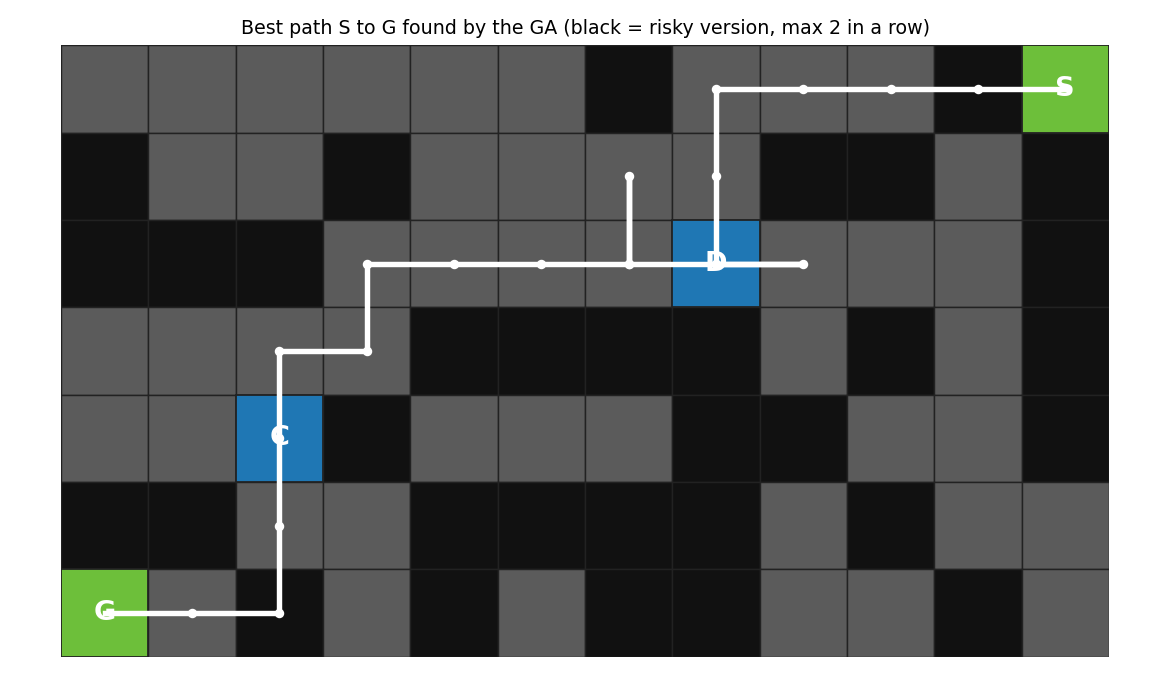

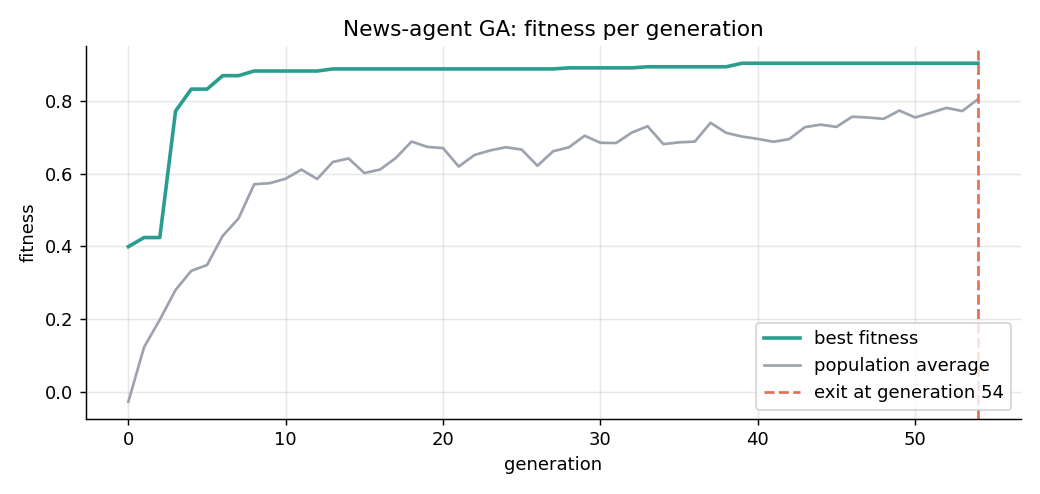

In [2]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('images/q02_chart*.png')):
    display(Image(p))